# Heart Disease Prediction

This notebook explores the UCI Heart Disease data, builds leakage-safe classification pipelines, compares three models, tunes the strongest baseline on the training set, explains it, and saves the complete pipeline.

## A. Load and inspect data

Read the provided CSV and inspect its size, data types, and missing values before making changes.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay)
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import shap

RANDOM_STATE = 42
DATA_PATH = Path("heart_disease_uci.csv")
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.dtypes.to_frame("dtype"))
display(df.isna().sum().to_frame("missing values"))
display(df.head())

Shape: (920, 16)


C:\Users\azaan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,dtype
id,int64
age,int64
sex,object
dataset,object
cp,object
trestbps,float64
chol,float64
fbs,object
restecg,object
thalch,float64


,missing values
id,0
age,0
sex,0
dataset,0
cp,0
trestbps,59
chol,30
fbs,90
restecg,2
thalch,55


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


## B. Clean data

Drop the row identifier and dataset source, convert the original 0–4 diagnosis into a binary outcome, remove rows without a known outcome, and let the model pipeline impute feature values.

In [2]:
data = df.drop(columns=["id", "dataset"]).copy()
data["num"] = (data["num"] > 0).astype(int)
data = data.dropna(subset=["num"])
X = data.drop(columns="num")
y = data["num"]
print("Cleaned shape:", data.shape)
print("Missing target rows removed; feature missing values:\n", X.isna().sum())

Cleaned shape: (920, 14)
Missing target rows removed; feature missing values:
 age           0
sex           0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
dtype: int64


## C. Exploratory data analysis

Review the target balance, correlations between numeric measurements, and distributions of selected features across the two target classes.

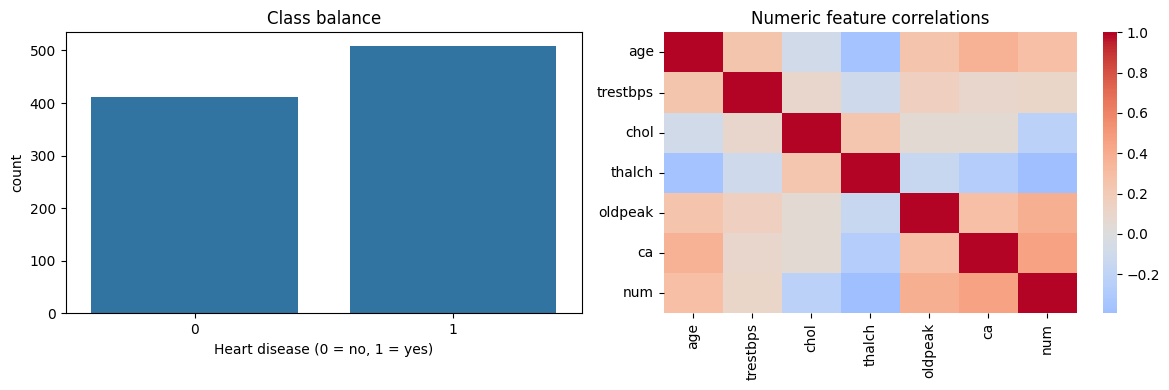

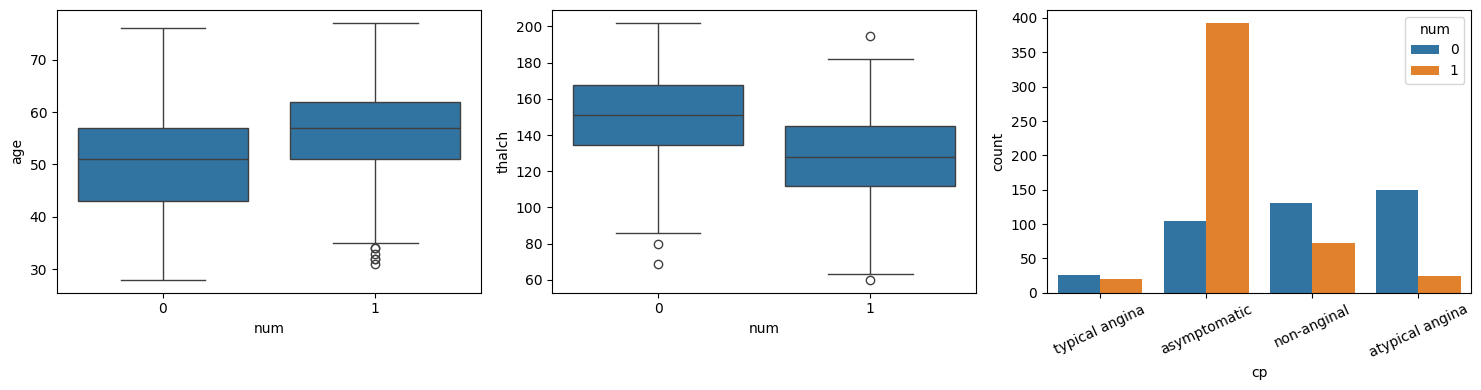

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=data, x="num", ax=axes[0])
axes[0].set(title="Class balance", xlabel="Heart disease (0 = no, 1 = yes)")
num_data = data.select_dtypes(include=np.number)
sns.heatmap(num_data.corr(), cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Numeric feature correlations")
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=data, x="num", y="age", ax=axes[0])
sns.boxplot(data=data, x="num", y="thalch", ax=axes[1])
sns.countplot(data=data, x="cp", hue="num", ax=axes[2])
axes[2].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

## D. Preprocessing and split

All imputers, scaling, and one-hot encoding are fitted inside the pipeline using training folds only. The held-out split is stratified and uses the requested random seed.

In [4]:
categorical = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]
numeric = [column for column in X.columns if column not in categorical]
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric),
    ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical),
])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (736, 13) Test: (184, 13)


## E. Train baseline models

Fit logistic regression, random forest, and XGBoost with the same preprocessing pipeline.

In [5]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                             subsample=0.9, colsample_bytree=0.9, eval_metric="logloss",
                             random_state=RANDOM_STATE, n_jobs=-1),
}
pipelines = {name: Pipeline([("preprocess", preprocessor), ("model", model)]) for name, model in models.items()}
for pipeline in pipelines.values():
    pipeline.fit(X_train, y_train)
print("Trained:", ", ".join(pipelines))

Trained: Logistic Regression, Random Forest, XGBoost


## F. Evaluate models

Compare held-out accuracy, precision, recall, F1, and ROC-AUC. Confusion matrices and ROC curves show each model's test-set behavior.

,Accuracy,Precision,Recall,F1,ROC-AUC
Random Forest,0.864,0.860,0.902,0.880,0.924
XGBoost,0.859,0.858,0.892,0.875,0.910
Logistic Regression,0.842,0.841,0.882,0.861,0.904


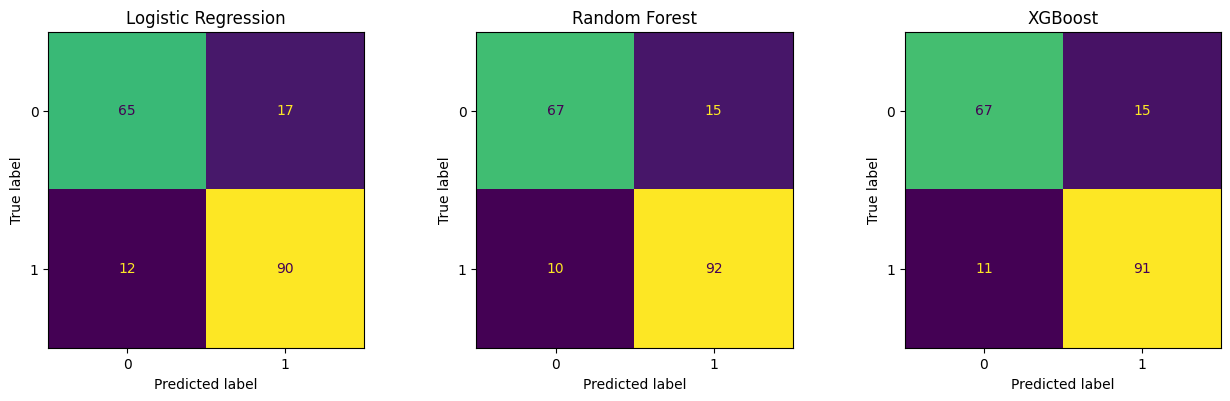

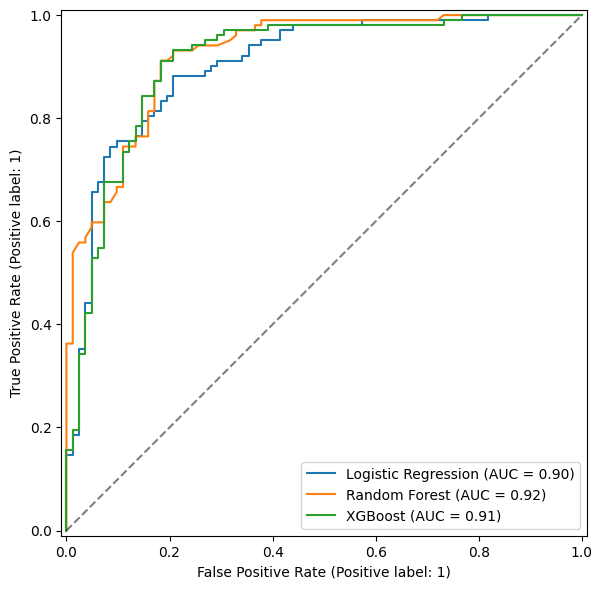

Best baseline by ROC-AUC: Random Forest


In [6]:
def evaluate(model, X_eval, y_eval):
    pred = model.predict(X_eval)
    prob = model.predict_proba(X_eval)[:, 1]
    return {"Accuracy": accuracy_score(y_eval, pred), "Precision": precision_score(y_eval, pred, zero_division=0),
            "Recall": recall_score(y_eval, pred, zero_division=0), "F1": f1_score(y_eval, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_eval, prob)}

results = pd.DataFrame({name: evaluate(model, X_test, y_test) for name, model in pipelines.items()}).T
display(results.sort_values("ROC-AUC", ascending=False).style.format("{:.3f}"))
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, model) in zip(axes, pipelines.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(7, 6))
for name, model in pipelines.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.tight_layout()
plt.show()
best_name = results["ROC-AUC"].idxmax()
print("Best baseline by ROC-AUC:", best_name)

## G. Tune the best baseline

Select the best baseline by ROC-AUC, then tune its model parameters using five-fold stratified cross-validation and recall scoring on training data only.

In [7]:
search_spaces = {
    "Logistic Regression": {"model__C": [0.05, 0.1, 0.5, 1, 2, 5, 10]},
    "Random Forest": {"model__n_estimators": [200, 300, 500], "model__max_depth": [None, 4, 8, 12],
                      "model__min_samples_leaf": [1, 2, 4], "model__max_features": ["sqrt", 0.8]},
    "XGBoost": {"model__n_estimators": [150, 250, 350], "model__max_depth": [2, 3, 4],
                "model__learning_rate": [0.03, 0.05, 0.1], "model__subsample": [0.8, 1.0],
                "model__colsample_bytree": [0.8, 1.0]},
}
search = RandomizedSearchCV(pipelines[best_name], search_spaces[best_name], n_iter=10, scoring="recall",
                            cv=5, random_state=RANDOM_STATE, n_jobs=-1, refit=True)
search.fit(X_train, y_train)
final_model = search.best_estimator_
print("Best parameters:", search.best_params_)
print("Best CV recall:", round(search.best_score_, 3))
final_metrics = evaluate(final_model, X_test, y_test)
print("Tuned test metrics:")
display(pd.Series(final_metrics, name="Tuned " + best_name).to_frame().T.style.format("{:.3f}"))

Best parameters: {'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 12}
Best CV recall: 0.857
Tuned test metrics:


,Accuracy,Precision,Recall,F1,ROC-AUC
Tuned Random Forest,0.870,0.868,0.902,0.885,0.925


## H. Explain the final model

Show the strongest transformed features using model coefficients or tree importances, and summarize SHAP values on a small sample of held-out rows.

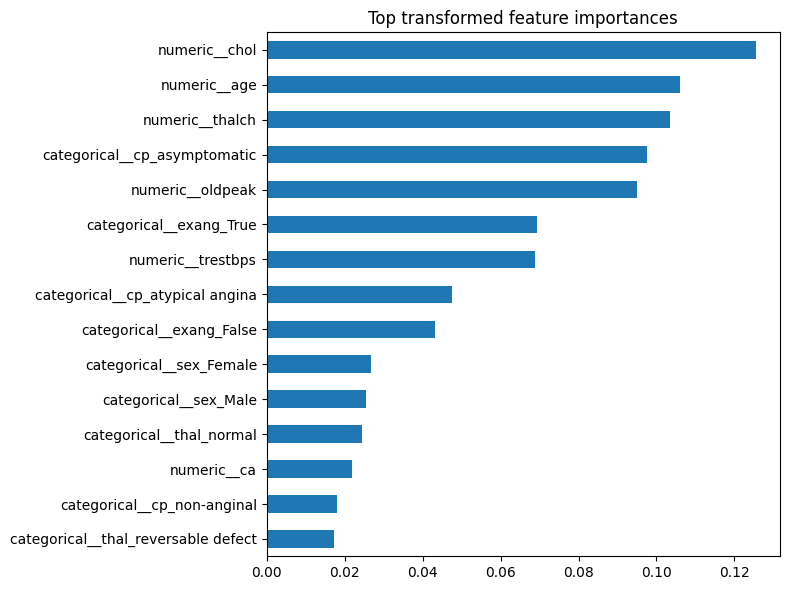

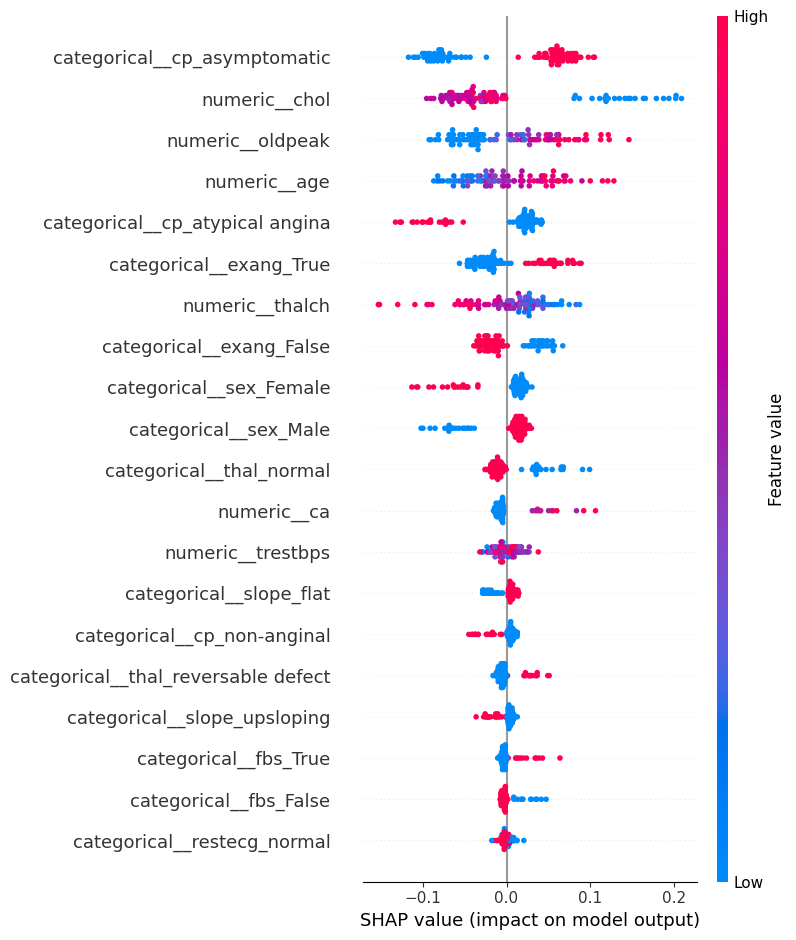

In [8]:
feature_names = final_model.named_steps["preprocess"].get_feature_names_out()
estimator = final_model.named_steps["model"]
if hasattr(estimator, "feature_importances_"):
    importance = estimator.feature_importances_
else:
    importance = np.abs(estimator.coef_).ravel()
importance_series = pd.Series(importance, index=feature_names).sort_values().tail(15)
importance_series.plot(kind="barh", figsize=(8, 6), title="Top transformed feature importances")
plt.tight_layout()
plt.show()
X_explain = final_model.named_steps["preprocess"].transform(X_test.iloc[:100])
if hasattr(X_explain, "toarray"):
    X_explain = X_explain.toarray()
explainer = shap.Explainer(estimator, X_explain, feature_names=feature_names)
shap_values = explainer(X_explain, check_additivity=False)
if len(shap_values.shape) == 3:
    shap.summary_plot(shap_values[:, :, 1], X_explain, feature_names=feature_names, show=True)
else:
    shap.summary_plot(shap_values, X_explain, feature_names=feature_names, show=True)

## I. Save the full pipeline

Save the tuned preprocessing and classifier together so future predictions apply the same cleaning transforms learned from training data.

In [9]:
joblib.dump(final_model, "model.pkl")
print("Saved model.pkl")

Saved model.pkl
